# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Dewi Ainun Amaliah]
- **Email:** [ds009b6x0440@student.devacademy.id]
- **ID Dicoding:** [DS009B6X0440]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

## Menentukan Pertanyaan Bisnis
- **Pertanyaan 1:** Bagaimana perbandingan rata-rata dan total penyewaan sepeda (`cnt`) antara kondisi cuaca cerah (`weathersit = 1`) dengan kondisi cuaca buruk/hujan (`weathersit = 3` dan `4`) di setiap musim (`season`) sepanjang periode tahun 2011 hingga 2012 untuk menentukan alokasi ketersediaan armada?
  - *Specific:* Fokus membandingkan jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim.
  - *Measurable:* Dihitung menggunakan metrik rata-rata (*mean*) dan total (*sum*) dari kolom `cnt`.
  - *Action-Oriented:* Menjadi dasar pengambilan keputusan untuk alokasi jumlah unit sepeda yang beroperasi serta penjadwalan *maintenance*.
  - *Relevant:* Kondisi cuaca dan pergantian musim berkaitan langsung dengan fluktuasi permintaan operasional *bike sharing*.
  - *Time-bound:* Dibatasi pada rentang waktu data historis tahun 2011 hingga 2012.

- **Pertanyaan 2:** Pada jam berapa saja (`hr`) terjadi lonjakan tertinggi (*peak hours*) penyewaan sepeda oleh pengguna terdaftar (`registered`) dibandingkan pengguna biasa (`casual`) pada hari kerja (`workingday = 1`) versus hari libur (`workingday = 0`) selama tahun 2011–2012?
  - *Specific:* Fokus pada pola jam operasional (`hr`) antara segmen pengguna `registered` dan `casual` di hari kerja vs hari libur.
  - *Measurable:* Diukur melalui rata-rata jumlah penyewaan per jam pada kolom `registered` dan `casual`.
  - *Action-Oriented:* Memberikan arahan waktu terbaik untuk redistribusi stok sepeda antarstasiun dan penentuan jam promosi akhir pekan.
  - *Relevant:* Mencegah kekosongan unit sepeda (*stockout*) pada jam sibuk komuter dan memaksimalkan potensi pengguna rekreasi.
  - *Time-bound:* Dibatasi pada periode operasional tahun 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data
Memuat tabel `day.csv` dan `hour.csv` dari Bike Sharing Dataset ke dalam DataFrame.

#### Load df ...

In [2]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

display(day_df.head())
display(hour_df.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Tabel `day_df` berhasil dimuat dengan menampilkan 5 baris pertama (tanggal `2011-01-01` hingga `2011-01-05`) yang terdiri dari 16 kolom (`instant`, `dteday`, `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`, `temp`, `atemp`, `hum`, `windspeed`, `casual`, `registered`, dan `cnt`). Terlihat bahwa nilai `cnt` merupakan penjumlahan dari penyewa `casual` dan `registered` (misalnya pada `2011-01-01`: `331 + 654 = 985`).
- Tabel `hour_df` berhasil dimuat dengan menampilkan 5 baris pertama pada tanggal `2011-01-01` yang terdiri dari 17 kolom. Perbedaan utamanya dengan `day_df` adalah adanya kolom `hr` (jam `0` hingga `4` pada 5 baris pertama) yang mencatat agregasi penyewaan sepeda beserta kondisi cuaca secara spesifik di setiap jamnya.

### Assessing Data

Mengidentifikasi permasalahan tipe data (*inaccurate data type*), nilai kosong (*missing value*), duplikasi data (*duplicate data*), serta nilai yang tidak akurat (*inaccurate value*) pada `day_df` dan `hour_df`.

#### Identifying ... problem

In [3]:
print("=== INFO DAY_DF ===")
day_df.info()
print("\n=== INFO HOUR_DF ===")
hour_df.info()

=== INFO DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== INFO HOUR_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1

In [4]:
print("\n=== PENGECEKAN MISSING VALUE & DUPLIKASI ===")
print("Missing value day_df  :", day_df.isna().sum().sum())
print("Missing value hour_df :", hour_df.isna().sum().sum())
print("Duplikasi day_df      :", day_df.duplicated().sum())
print("Duplikasi hour_df     :", hour_df.duplicated().sum())


=== PENGECEKAN MISSING VALUE & DUPLIKASI ===
Missing value day_df  : 0
Missing value hour_df : 0
Duplikasi day_df      : 0
Duplikasi hour_df     : 0


In [5]:
print("\n=== STATISTIK DESKRIPTIF DAY_DF ===")
display(day_df.describe())


=== STATISTIK DESKRIPTIF DAY_DF ===


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [6]:
print("\n=== PENGECEKAN INACCURATE VALUE (KELEMBAPAN = 0) ===")
print("Jumlah baris dengan hum == 0 di day_df  :", (day_df['hum'] == 0).sum())
print("Jumlah baris dengan hum == 0 di hour_df :", (hour_df['hum'] == 0).sum())


=== PENGECEKAN INACCURATE VALUE (KELEMBAPAN = 0) ===
Jumlah baris dengan hum == 0 di day_df  : 1
Jumlah baris dengan hum == 0 di hour_df : 22


**Steps to Take:**
- Mengubah tipe data kolom `dteday` pada `day_df` dan `hour_df` dari `object` menjadi `datetime`.
- Mengganti nilai tidak akurat (*inaccurate value*) pada kolom kelembapan (`hum == 0`) sebanyak 1 baris di `day_df` dan 22 baris di `hour_df` menggunakan nilai median (`0.626667` pada `day_df`).
- Melakukan *mapping* nilai angka (`int64`) pada kolom kategorikal (`season`, `yr`, `weathersit`, `workingday`, `weekday`) menjadi label deskriptif, serta mengembalikan (*denormalize*) nilai `temp`, `atemp`, `hum`, dan `windspeed` ke satuan aslinya.

**Insight:** (Opsional)
- Berdasarkan output `info()` dan pengecekan *missing value* serta duplikasi, `day_df` memiliki **731 baris** (16 kolom) dan `hour_df` memiliki **17.379 baris** (17 kolom) yang seluruhnya lengkap (*non-null*) dengan jumlah *missing value* **0** dan duplikasi data **0**.
- **Inaccurate Data Type:** Kolom tanggal `dteday` pada kedua DataFrame masih terdeteksi sebagai tipe data `object`, dan fitur-fitur kategorikal (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`) masih bertipe `int64`.
- **Inaccurate Value:** Dari tabel `day_df.describe()`, rata-rata total penyewaan harian (`cnt`) berada di angka **4.504,35** (rentang `min` **22** hingga `max` **8.714**), namun ditemukan nilai minimum kelembapan (`hum`) sebesar **0.000000**. Hasil pengecekan mengonfirmasi adanya `hum == 0` sebanyak **1 baris** di `day_df` dan **22 baris** di `hour_df` yang perlu dibersihkan karena kelembapan udara alami tidak mungkin bernilai 0%.

### Cleaning Data

Memperbaiki tipe data dteday, mengimputasi nilai tidak akurat pada kolom hum, serta melakukan mapping label kategorikal dan denormalisasi nilai cuaca.

In [7]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Mengganti inaccurate value (hum == 0) dengan nilai median
day_df['hum'] = day_df['hum'].replace(0, day_df['hum'].median())
hour_df['hum'] = hour_df['hum'].replace(0, hour_df['hum'].median())

# 3. Mapping label kategorikal dan denormalisasi nilai cuaca
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
year_map = {0: '2011', 1: '2012'}
weather_map = {
    1: 'Cerah/Berawan',
    2: 'Berkabut/Mendung',
    3: 'Hujan/Salju Ringan',
    4: 'Cuaca Ekstrem'
}
workingday_map = {0: 'Hari Libur', 1: 'Hari Kerja'}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}

for df in [day_df, hour_df]:
    df['season_label'] = df['season'].map(season_map)
    df['yr_label'] = df['yr'].map(year_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['workingday_label'] = df['workingday'].map(workingday_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)

    # Denormalisasi sesuai dokumentasi Readme.txt
    df['temp_celsius'] = df['temp'] * 41
    df['atemp_celsius'] = df['atemp'] * 50
    df['hum_percent'] = df['hum'] * 100
    df['windspeed_original'] = df['windspeed'] * 67

print("Jumlah baris hum == 0 di day_df setelah cleaning :", (day_df['hum'] == 0).sum())
print("Jumlah baris hum == 0 di hour_df setelah cleaning:", (hour_df['hum'] == 0).sum())
display(day_df[['dteday', 'season_label', 'yr_label', 'weather_label', 'temp_celsius', 'hum_percent', 'cnt']].head())

Jumlah baris hum == 0 di day_df setelah cleaning : 0
Jumlah baris hum == 0 di hour_df setelah cleaning: 0


,dteday,season_label,yr_label,weather_label,temp_celsius,hum_percent,cnt
0,2011-01-01,Spring,2011,Berkabut/Mendung,14.110847,80.5833,985
1,2011-01-02,Spring,2011,Berkabut/Mendung,14.902598,69.6087,801
2,2011-01-03,Spring,2011,Cerah/Berawan,8.050924,43.7273,1349
3,2011-01-04,Spring,2011,Cerah/Berawan,8.200000,59.0435,1562
4,2011-01-05,Spring,2011,Cerah/Berawan,9.305237,43.6957,1600


**Insight:**
- Nilai tidak akurat (*inaccurate value*) pada kolom kelembapan (`hum == 0`) telah berhasil diimputasi dengan nilai median, terbukti dari jumlah baris `hum == 0` pada `day_df` dan `hour_df` yang kini bernilai **0**.
- Tipe data `dteday` telah terkonversi menjadi `datetime`, serta kolom kategorikal berhasil diubah menjadi label deskriptif pada `season_label` (*Spring*), `yr_label` (*2011*), dan `weather_label` (*Berkabut/Mendung*, *Cerah/Berawan*).
- Parameter cuaca berhasil dikembalikan ke skala aslinya (*denormalized*), seperti yang terlihat pada 5 baris pertama di mana suhu `temp_celsius` berkisar antara **8,05°C hingga 14,90°C** dan kelembapan `hum_percent` berkisar antara **43,69% hingga 80,58%**.

## Exploratory Data Analysis (EDA)

### Explore `day_df` dan `hour_df`

In [8]:
# 1. Eksplorasi rata-rata dan total penyewaan berdasarkan Kondisi Cuaca (day_df)
print("=== AGREGASI PENYEWAAN BERDASARKAN KONDISI CUACA ===")
weather_eda = day_df.groupby(by='weather_label').agg({
    'instant': 'count',
    'cnt': ['mean', 'sum', 'min', 'max']
}).reset_index()
display(weather_eda)

=== AGREGASI PENYEWAAN BERDASARKAN KONDISI CUACA ===


weather_label instant          cnt                    
                        count         mean      sum  min   max
0    Berkabut/Mendung     247  4035.862348   996858  605  8362
1       Cerah/Berawan     463  4876.786177  2257952  431  8714
2  Hujan/Salju Ringan      21  1803.285714    37869   22  4639

In [9]:
# 2. Eksplorasi penyewaan berdasarkan Musim dan Kondisi Cuaca (Menjawab Pertanyaan 1)
print("\n=== AGREGASI PENYEWAAN BERDASARKAN MUSIM & KONDISI CUACA ===")
season_weather_eda = day_df.groupby(by=['season_label', 'weather_label']).agg({
    'cnt': ['count', 'mean', 'sum']
}).reset_index()
display(season_weather_eda)


=== AGREGASI PENYEWAAN BERDASARKAN MUSIM & KONDISI CUACA ===


season_label       weather_label   cnt                     
                                    count         mean     sum
0          Fall    Berkabut/Mendung    48  5222.479167  250679
1          Fall       Cerah/Berawan   136  5878.257353  799443
2          Fall  Hujan/Salju Ringan     4  2751.750000   11007
3        Spring    Berkabut/Mendung    66  2357.166667  155573
4        Spring       Cerah/Berawan   111  2811.135135  312036
5        Spring  Hujan/Salju Ringan     4   934.750000    3739
6        Summer    Berkabut/Mendung    68  4236.705882  288096
7        Summer       Cerah/Berawan   113  5548.548673  626986
8        Summer  Hujan/Salju Ringan     3  1169.000000    3507
9        Winter    Berkabut/Mendung    65  4654.000000  302510
10       Winter       Cerah/Berawan   103  5043.563107  519487
11       Winter  Hujan/Salju Ringan    10  1961.600000   19616

In [10]:
# 3. Eksplorasi rata-rata penyewaan per jam berdasarkan Hari Kerja vs Hari Libur (Menjawab Pertanyaan 2)
print("\n=== TOP 10 JAM DENGAN RATA-RATA PENYEWAAN TERTINGGI (HARI KERJA VS HARI LIBUR) ===")
hourly_eda = hour_df.groupby(by=['workingday_label', 'hr']).agg({
    'registered': 'mean',
    'casual': 'mean',
    'cnt': ['mean', 'sum']
}).reset_index()
display(hourly_eda.sort_values(by=('cnt', 'mean'), ascending=False).head(10))


=== TOP 10 JAM DENGAN RATA-RATA PENYEWAAN TERTINGGI (HARI KERJA VS HARI LIBUR) ===


workingday_label  hr  registered      casual         cnt        
                               mean        mean        mean     sum
17       Hari Kerja  17  468.394790   56.895792  525.290581  262120
18       Hari Kerja  18  441.775100   50.451807  492.226908  245129
8        Hari Kerja   8  454.741935   22.264113  477.006048  236595
37       Hari Libur  13  236.307359  136.424242  372.731602   86101
36       Hari Libur  12  240.012987  126.246753  366.259740   84606
38       Hari Libur  14  225.051948  139.593074  364.645022   84233
39       Hari Libur  15  222.311688  136.502165  358.813853   82886
40       Hari Libur  16  224.112554  128.614719  352.727273   81480
19       Hari Kerja  19  307.379518   41.022088  348.401606  173504
41       Hari Libur  17  211.735931  111.813853  323.549784   74740

**Insight:**
- Berdasarkan agregasi kondisi cuaca pada `day_df`, kondisi **Cerah/Berawan** merupakan kondisi yang paling sering terjadi (**463 hari**) sekaligus mencatatkan rata-rata penyewaan tertinggi sebesar **4.876,79 unit/hari** (total **2.257.952** penyewaan), disusul **Berkabut/Mendung** (**247 hari**) dengan rata-rata **4.035,86 unit/hari** (total **996.858** penyewaan). Sebaliknya, kondisi **Hujan/Salju Ringan** (**21 hari**) mengalami penurunan rata-rata penyewaan secara drastis menjadi **1.803,29 unit/hari** (total **37.869** penyewaan), serta tidak ada satu pun hari (0 hari) yang tercatat dalam kategori *Cuaca Ekstrem* pada agregasi harian.
- Berdasarkan kombinasi musim dan cuaca, rata-rata penyewaan tertinggi dicapai pada musim **Fall (Gugur)** saat cuaca **Cerah/Berawan** sebesar **5.878,26 unit/hari** (total **799.443** penyewaan) dan musim **Summer (Panas)** saat cuaca **Cerah/Berawan** sebesar **5.548,55 unit/hari** (total **626.986** penyewaan). Sementara itu, rata-rata penyewaan paling rendah terjadi pada musim **Spring (Semi)** saat kondisi **Hujan/Salju Ringan** yang hanya menyentuh **934,75 unit/hari** (total **3.739** penyewaan).
- Berdasarkan tabel 10 jam tersibuk pada `hour_df`, tiga puncak tertinggi berada pada **Hari Kerja**, yaitu pukul **17:00** (rata-rata `cnt` **525,29**/jam; didominasi `registered` sebesar **468,39**/jam), pukul **18:00** (rata-rata `cnt` **492,23**/jam; `registered` **441,78**/jam), dan pukul **08:00** (rata-rata `cnt` **477,01**/jam; `registered` **454,74**/jam). Sebaliknya, pada **Hari Libur**, jam tersibuk terkonsentrasi pada siang hingga sore hari yakni pukul **13:00** (**372,73**/jam), pukul **12:00** (**366,26**/jam), pukul **14:00** (**364,65**/jam), pukul **15:00** (**358,81**/jam), dan pukul **16:00** (**352,73**/jam), dengan rata-rata pengguna `casual` mencapai **126,25 hingga 139,59 penyewa/jam** (lebih dari 2 kali lipat rata-rata `casual` pada jam sibuk hari kerja).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_2418/3061244306.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


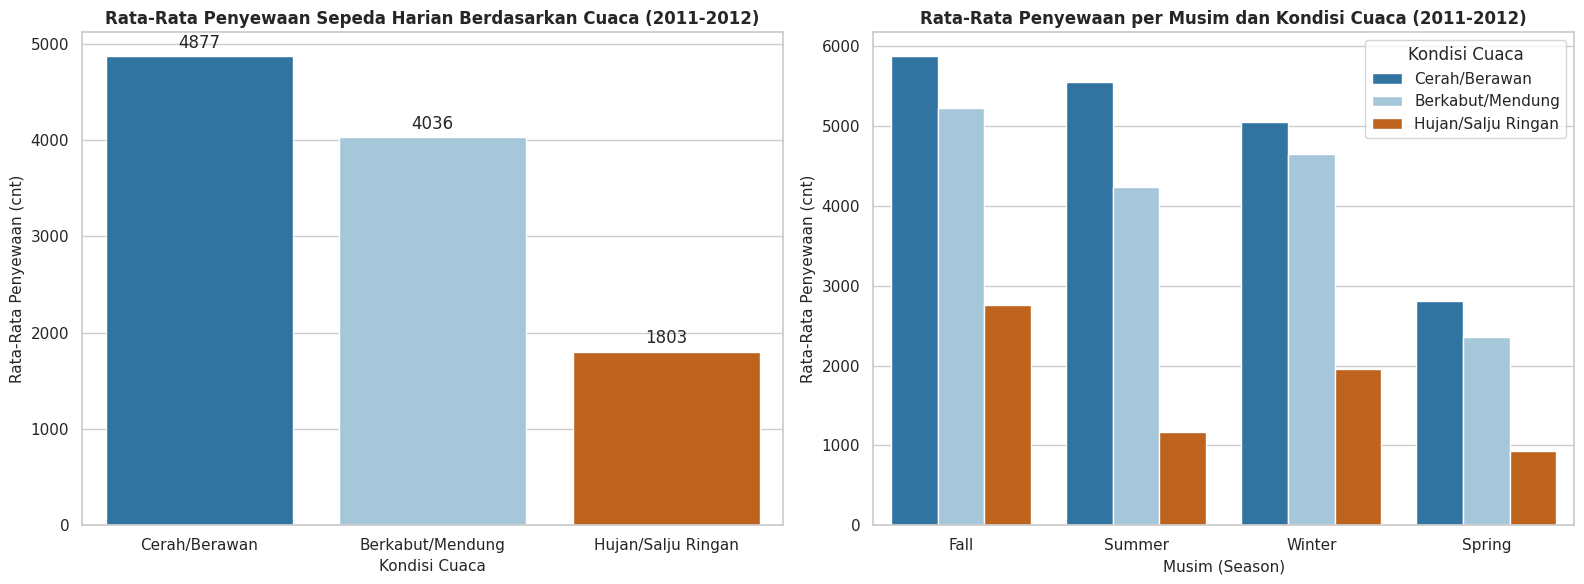

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

weather_order = ['Cerah/Berawan', 'Berkabut/Mendung', 'Hujan/Salju Ringan']
season_order = ['Fall', 'Summer', 'Winter', 'Spring']

# Visualisasi 1A: Rata-rata penyewaan harian berdasarkan kondisi cuaca
sns.barplot(
    data=day_df,
    x='weather_label',
    y='cnt',
    order=weather_order,
    palette=['#1f77b4', '#9ecae1', '#d95f02'],
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Rata-Rata Penyewaan Sepeda Harian Berdasarkan Cuaca (2011-2012)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kondisi Cuaca', fontsize=11)
axes[0].set_ylabel('Rata-Rata Penyewaan (cnt)', fontsize=11)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3)

# Visualisasi 1B: Rata-rata penyewaan berdasarkan musim dan cuaca
sns.barplot(
    data=day_df,
    x='season_label',
    y='cnt',
    hue='weather_label',
    order=season_order,
    hue_order=weather_order,
    palette=['#1f77b4', '#9ecae1', '#d95f02'],
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Rata-Rata Penyewaan per Musim dan Kondisi Cuaca (2011-2012)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Musim (Season)', fontsize=11)
axes[1].set_ylabel('Rata-Rata Penyewaan (cnt)', fontsize=11)
axes[1].legend(title='Kondisi Cuaca')

plt.tight_layout()
plt.show()

### Pertanyaan 2:

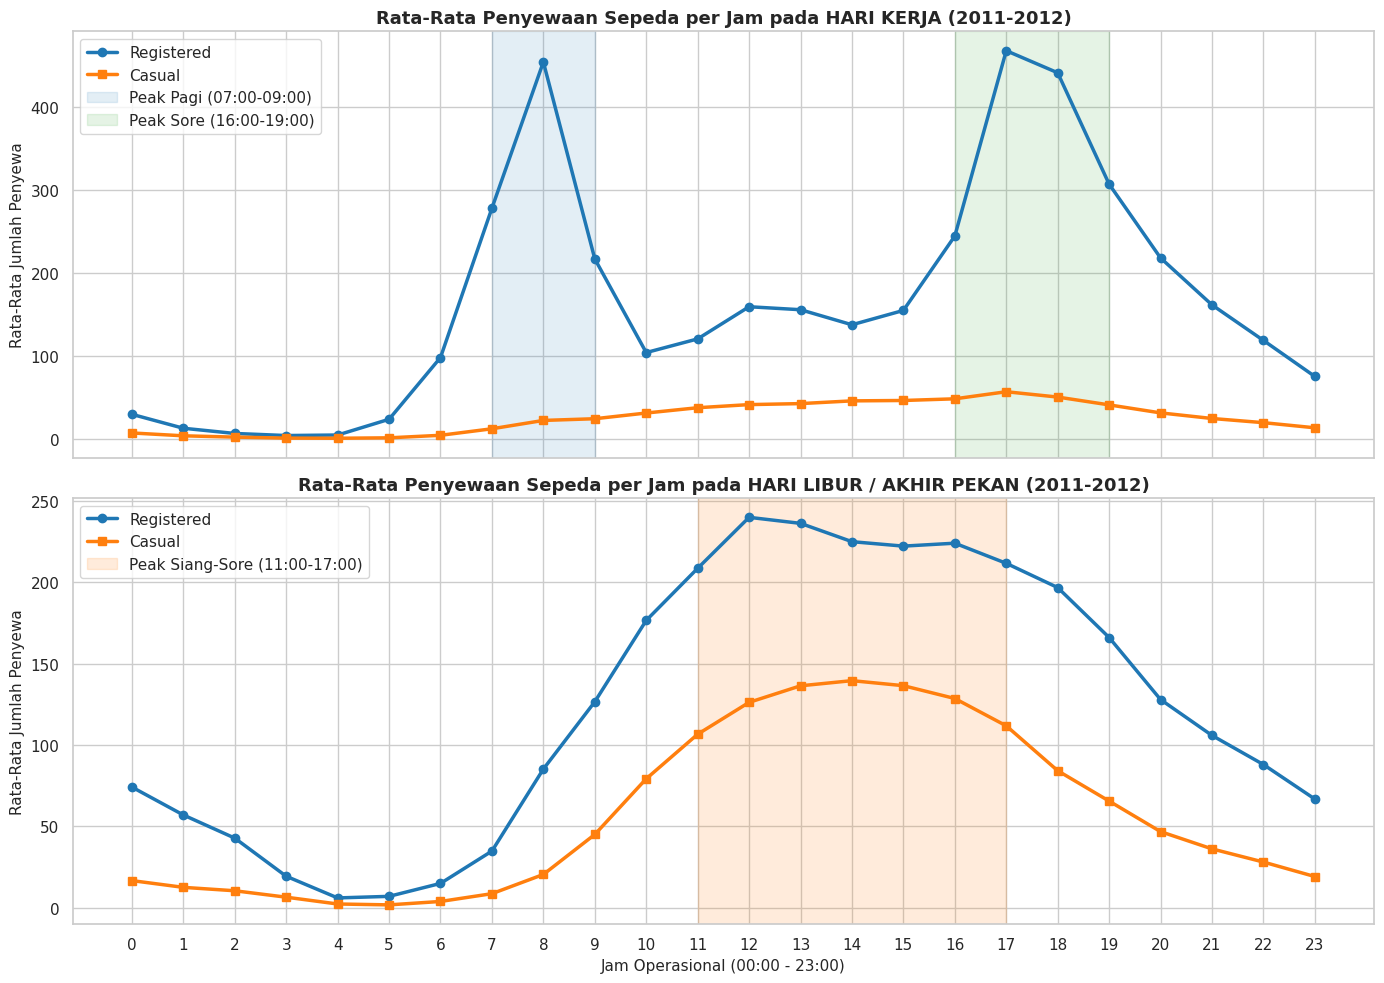

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

workday_hourly = hour_df[hour_df['workingday'] == 1].groupby('hr')[['registered', 'casual']].mean().reset_index()
holiday_hourly = hour_df[hour_df['workingday'] == 0].groupby('hr')[['registered', 'casual']].mean().reset_index()

# Plot Hari Kerja
axes[0].plot(workday_hourly['hr'], workday_hourly['registered'], marker='o', linewidth=2.5, color='#1f77b4', label='Registered')
axes[0].plot(workday_hourly['hr'], workday_hourly['casual'], marker='s', linewidth=2.5, color='#ff7f0e', label='Casual')
axes[0].set_title('Rata-Rata Penyewaan Sepeda per Jam pada HARI KERJA (2011-2012)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Rata-Rata Jumlah Penyewa', fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].axvspan(7, 9, color='#1f77b4', alpha=0.12, label='Peak Pagi (07:00-09:00)')
axes[0].axvspan(16, 19, color='#2ca02c', alpha=0.12, label='Peak Sore (16:00-19:00)')
axes[0].legend(loc='upper left')

# Plot Hari Libur
axes[1].plot(holiday_hourly['hr'], holiday_hourly['registered'], marker='o', linewidth=2.5, color='#1f77b4', label='Registered')
axes[1].plot(holiday_hourly['hr'], holiday_hourly['casual'], marker='s', linewidth=2.5, color='#ff7f0e', label='Casual')
axes[1].set_title('Rata-Rata Penyewaan Sepeda per Jam pada HARI LIBUR / AKHIR PEKAN (2011-2012)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Jam Operasional (00:00 - 23:00)', fontsize=11)
axes[1].set_ylabel('Rata-Rata Jumlah Penyewa', fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].axvspan(11, 17, color='#ff7f0e', alpha=0.15, label='Peak Siang-Sore (11:00-17:00)')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Visualisasi Pertanyaan 1:** Berdasarkan grafik *Rata-Rata Penyewaan Sepeda Harian Berdasarkan Cuaca (2011-2012)*, kondisi cuaca **Cerah/Berawan** menghasilkan rata-rata penyewaan tertinggi sebesar **4.877 unit/hari**, menurun pada kondisi **Berkabut/Mendung** menjadi **4.036 unit/hari**, dan turun drastis sebesar 63% pada kondisi **Hujan/Salju Ringan** menjadi **1.803 unit/hari**. Grafik *Rata-Rata Penyewaan per Musim dan Kondisi Cuaca (2011-2012)* juga memperlihatkan bahwa pola dominasi cuaca cerah ini konsisten di keempat musim dengan urutan volume tertinggi berada pada musim **Fall**, disusul **Summer**, **Winter**, dan terendah pada **Spring** (puncak tertinggi di musim **Fall** saat cuaca cerah sebesar **5.878 unit/hari** dan terendah di musim **Spring** saat hujan/salju ringan sebesar **935 unit/hari**).
- **Visualisasi Pertanyaan 2:** Grafik *Rata-Rata Penyewaan Sepeda per Jam pada HARI KERJA (2011-2012)* menunjukkan pola dua puncak tajam (*bimodal*) yang didominasi oleh pengguna **Registered** pada rentang **Peak Pagi (07:00-09:00)** dengan puncak di pukul **08:00** (**454,74 penyewa/jam**) dan **Peak Sore (16:00-19:00)** dengan puncak di pukul **17:00** (**468,39 penyewa/jam**) serta pukul **18:00** (**441,78 penyewa/jam**), sedangkan pengguna **Casual** cenderung rendah (di bawah 57 penyewa/jam). Sebaliknya, pada grafik *HARI LIBUR / AKHIR PEKAN (2011-2012)*, kurva membentuk satu puncak landai (*unimodal*) pada rentang **Peak Siang-Sore (11:00-17:00)**, di mana rata-rata penyewa **Registered** memuncak pada pukul **12:00-13:00** (**240,01** dan **236,31 penyewa/jam**) diikuti lonjakan signifikan pengguna **Casual** yang mencapai puncak pada pukul **13:00-15:00** (**136,42 hingga 139,59 penyewa/jam**).

## Analisis Lanjutan (Opsional)
Menerapkan teknik **Clustering (Tanpa Algoritma Machine Learning)** menggunakan metode **Manual Grouping** untuk mengelompokkan waktu operasional harian (`time_of_day`) dan metode **Binning** (`pd.cut`) untuk mengelompokkan tingkat kenyamanan suhu udara (`temp_category`).

In [13]:
# 1. Manual Grouping berdasarkan Kategori Waktu Operasional pada hour_df
def categorize_time(hr):
    if 5 <= hr < 11:
        return 'Pagi (05:00-10:59)'
    elif 11 <= hr < 15:
        return 'Siang (11:00-14:59)'
    elif 15 <= hr < 19:
        return 'Sore (15:00-18:59)'
    else:
        return 'Malam (19:00-04:59)'

hour_df['time_of_day'] = hour_df['hr'].apply(categorize_time)

In [14]:
# 2. Binning berdasarkan Kategori Suhu (Celsius) pada day_df dan hour_df
bins = [0, 15, 26, 45]
labels = ['Dingin (<15°C)', 'Sejuk/Ideal (15-26°C)', 'Panas (>26°C)']
day_df['temp_category'] = pd.cut(day_df['temp_celsius'], bins=bins, labels=labels)
hour_df['temp_category'] = pd.cut(hour_df['temp_celsius'], bins=bins, labels=labels)

In [15]:
# Menampilkan tabel agregasi hasil clustering
print("=== CLUSTERING WAKTU HARI (MANUAL GROUPING) ===")
display(hour_df.groupby('time_of_day', observed=False)['cnt'].agg(['count', 'mean', 'sum']).reset_index())

=== CLUSTERING WAKTU HARI (MANUAL GROUPING) ===


,time_of_day,count,mean,sum
0,Malam (19:00-04:59),7199,106.762745,768585
1,Pagi (05:00-10:59),4350,177.071264,770260
2,Siang (11:00-14:59),2913,239.033642,696305
3,Sore (15:00-18:59),2917,362.539938,1057529


In [16]:
print("\n=== CLUSTERING KATEGORI SUHU (BINNING) ===")
display(day_df.groupby('temp_category', observed=False)['cnt'].agg(['count', 'mean', 'sum']).reset_index())


=== CLUSTERING KATEGORI SUHU (BINNING) ===


,temp_category,count,mean,sum
0,Dingin (<15°C),221,2833.316742,626163
1,Sejuk/Ideal (15-26°C),295,4941.596610,1457771
2,Panas (>26°C),215,5622.069767,1208745


/tmp/ipykernel_2418/1545560638.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_2418/1545560638.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


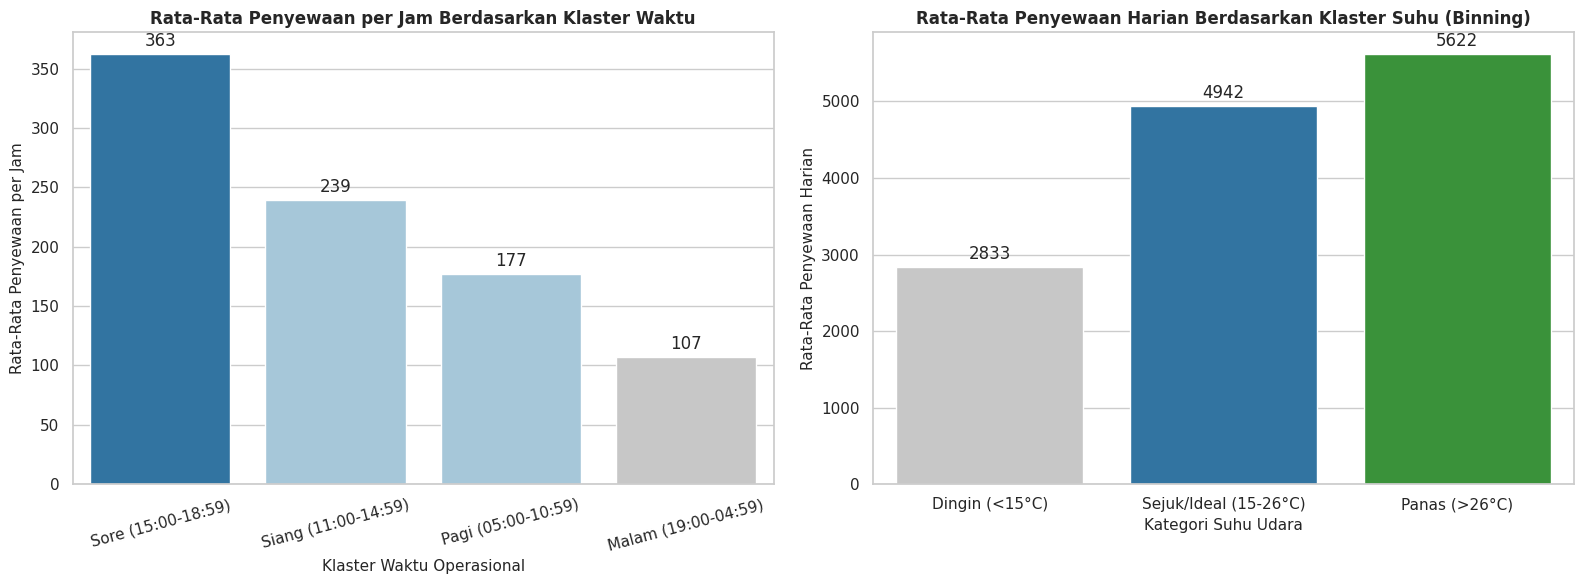

In [17]:
# Visualisasi Hasil Clustering
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

time_order = ['Sore (15:00-18:59)', 'Siang (11:00-14:59)', 'Pagi (05:00-10:59)', 'Malam (19:00-04:59)']
sns.barplot(
    data=hour_df,
    x='time_of_day',
    y='cnt',
    order=time_order,
    palette=['#1f77b4', '#9ecae1', '#9ecae1', '#c7c7c7'],
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Rata-Rata Penyewaan per Jam Berdasarkan Klaster Waktu', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Klaster Waktu Operasional', fontsize=11)
axes[0].set_ylabel('Rata-Rata Penyewaan per Jam', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3)

sns.barplot(
    data=day_df,
    x='temp_category',
    y='cnt',
    palette=['#c7c7c7', '#1f77b4', '#2ca02c'],
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Rata-Rata Penyewaan Harian Berdasarkan Klaster Suhu (Binning)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kategori Suhu Udara', fontsize=11)
axes[1].set_ylabel('Rata-Rata Penyewaan Harian', fontsize=11)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

# Menyimpan dataset hasil olahan untuk digunakan pada Dashboard Streamlit
hour_df.to_csv("main_data.csv", index=False)

**Insight:** (Opsional)
- Berdasarkan **Manual Grouping Waktu Hari**, klaster **Sore (15:00-18:59)** merupakan periode paling produktif dengan rata-rata penyewaan tertinggi mencapai **362,54 unit/jam** (**363** pada grafik) dan total volume tertinggi sebesar **1.057.529 penyewaan** (dari 2.917 jam). Di posisi berikutnya adalah klaster **Siang (11:00-14:59)** dengan rata-rata **239,03 unit/jam** (total 696.305 penyewaan) dan **Pagi (05:00-10:59)** dengan rata-rata **177,07 unit/jam** (total 770.260 penyewaan). Sebaliknya, klaster **Malam (19:00-04:59)** memiliki intensitas rata-rata terendah yakni hanya **106,76 unit/jam** (**107** pada grafik) meskipun mencakup durasi jam terpanjang (7.199 jam).
- Berdasarkan **Binning Kategori Suhu**, klaster suhu **Panas (>26°C)** mencatatkan rata-rata penyewaan harian tertinggi sebesar **5.622,07 unit/hari** (**5.622** pada grafik; total 1.208.745 penyewaan dari 215 hari), diikuti klaster **Sejuk/Ideal (15-26°C)** yang memiliki rata-rata **4.941,60 unit/hari** (**4.942** pada grafik) namun menyumbang total volume penyewaan terbesar yakni **1.457.771 penyewaan** karena durasi harinya paling banyak (295 hari). Sebaliknya, ketika suhu berada pada klaster **Dingin (<15°C)** (221 hari), rata-rata penyewaan turun drastis menjadi **2.833,32 unit/hari** (**2.833** pada grafik; total 626.163 penyewaan).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca dan musim memberikan pengaruh yang sangat signifikan terhadap jumlah penyewaan sepeda selama periode 2011–2012. Kondisi cuaca **Cerah/Berawan** mencatat rata-rata penyewaan tertinggi sebesar **4.876,79 unit/hari** (total **2.257.952** penyewaan dari 463 hari), menurun sebesar 17,2% pada kondisi **Berkabut/Mendung** menjadi **4.035,86 unit/hari** (total **996.858** penyewaan dari 247 hari), dan anjlok sebesar **63%** pada kondisi **Hujan/Salju Ringan** menjadi hanya **1.803,29 unit/hari** (total **37.869** penyewaan dari 21 hari). Pola ini konsisten di seluruh musim, di mana **Musim Gugur (Fall)** saat cuaca cerah mencatat rata-rata tertinggi (**5.878,26 unit/hari**), disusul **Summer** (**5.548,55 unit/hari**), **Winter** (**5.043,56 unit/hari**), dan terendah pada **Musim Semi (Spring)** terutama saat hujan/salju ringan (**934,75 unit/hari**).
- **Conclusion pertanyaan 2:** Terdapat perbedaan pola jam lonjakan (*peak hours*) yang kontras antara hari kerja dan hari libur sepanjang tahun 2011–2012. Pada **Hari Kerja**, grafik membentuk pola *bimodal* (dua puncak tajam) yang didominasi oleh pengguna **Registered** pada jam berangkat kerja pukul **08:00 pagi** (rata-rata total **477,01 unit/jam**; `registered` **454,74 unit/jam**) dan jam pulang kerja pukul **17:00–18:00 sore** (puncak tertinggi pukul 17:00 dengan rata-rata total **525,29 unit/jam**; `registered` **468,39 unit/jam**). Sebaliknya, pada **Hari Libur/Akhir Pekan**, grafik membentuk pola *unimodal* (satu puncak landai) pada rentang pukul **11:00 hingga 17:00** (puncak rata-rata total pada pukul 13:00 sebesar **372,73 unit/jam**), di mana rata-rata penyewa **Casual** melonjak lebih dari dua kali lipat hingga mencapai **126,25–139,59 unit/jam** pada pukul 12:00–16:00.

**Rekomendasi Action Item:**
- **Optimalisasi Alokasi Armada & Penjadwalan Maintenance Berbasis Musim, Cuaca, dan Suhu:** Mengoperasikan 100% kapasitas unit sepeda pada musim **Fall** dan **Summer** ketika cuaca **Cerah/Berawan** serta saat suhu berada di klaster **Sejuk/Ideal (15–26°C)** dan **Panas (>26°C)** (yang rata-rata permintaannya mencapai 4.942–5.622 unit/hari). Sebaliknya, jadwalkan perawatan berkala (*preventive maintenance*) armada pada musim **Spring**, pada hari bersuhu **Dingin (<15°C)** atau berprakiraan hujan, serta pada klaster waktu **Malam (19:00–04:59)** yang hanya memiliki rata-rata 107 penyewaan/jam.
- **Strategi Redistribusi Sepeda di Jam Komuter & Promosi Konversi Member Akhir Pekan:** Melakukan *restocking* dan redistribusi sepeda ke stasiun area pemukiman sebelum pukul **07:00 pagi** serta ke stasiun area perkantoran sebelumklaster waktu **Sore (15:00–18:59)** (khususnya menjelang puncak pukul 17:00–18:00) pada hari kerja untuk mencegah kekosongan unit bagi pengguna `registered`. Selain itu, luncurkan promo *Weekend Pass* atau insentif pendaftaran member pada rentang pukul **11:00–17:00** di hari libur/akhir pekan guna mengonversi tingginya pengguna `casual` menjadi pelanggan `registered`.

In [18]:
plt.tight_layout()
plt.show()

# Menyimpan dataset hasil olahan untuk digunakan pada Dashboard Streamlit
hour_df.to_csv("main_data.csv", index=False)

from google.colab import files
files.download("main_data.csv")

<Figure size 640x480 with 0 Axes>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>